# Studi Kasus 1: Make Sense of Data with Analysis and AI (Implementasi End-to-End CRISP-DM)

**Topik Webinar:** *Make Sense of Data with Analysis and AI*  
**Fokus Implementasi:** Tahapan analitik terstruktur menggunakan metodologi **[CRISP-DM (Cross-Industry Standard Process for Data Mining)](https://www.ibm.com/docs/en/spss-modeler/saas?topic=dm-crisp-help-overview)**, pra-pemrosesan data komprehensif (*Data Sanity Check*, *Entity Standardization*, *Outlier Winsorization*, *Imputation*), alur pemodelan modular bergaya **[KNIME Analytics Platform](https://www.knime.com/knime-analytics-platform)** yang dipadukan dengan ekstraksi aturan berbantuan AI, serta **Validasi Kewarasan Data & Pengawasan Kritis Manusia (*Human-in-the-Loop*)** dalam pengambilan keputusan bisnis.

### Skenario Bisnis & Dataset Realistis
Sebuah platform *B2B/B2C E-Commerce & SaaS Distribution* di Indonesia menghadapi peningkatan *Customer Churn* (pelanggan berhenti berlangganan) yang menggerus pendapatan bulanan. Tim Data diinstruksikan untuk:
1. **Business Understanding:** Memetakan biaya retensi (*Retention Promo Cost* = Rp 150.000/akun) terhadap potensi kerugian *Customer Lifetime Value* (LTV = 6x belanja bulanan).
2. **Data Understanding & Sanity Check:** Mengaudit data mentah (`dataset 01 ecommerce churn crispdm.csv`, 1.525 baris) yang mengandung anomali dunia nyata: duplikasi log, usia negatif (`-12 tahun`), *input error* nilai transaksi (`Rp 999.999.999`), inkonsistensi nama provinsi (`'jkt'`, `'Jakarta'`, `'DKI Jakarta'`), dan *missing values*.
3. **Data Preparation:** Membersihkan anomali, melakukan imputasi terstruktur, dan merekayasa fitur bisnis **RFM (*Recency, Frequency, Monetary*)**.
4. **Modeling (Modular Pipeline & AI Rule Synthesis):** Membangun ansambel prediktif (*Gradient Boosting* & *Regularized Logistic Regression*) serta asisten interpretasi berbasis aturan AI.
5. **Evaluation & Human-in-the-Loop Decision:** Mengoptimalkan *threshold* probabilitas berdasarkan kurva profit bersih (bukan sekadar akurasi buta) dan menerapkan *Human Critical Sanity Override* untuk akun *Enterprise VIP*.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="deep")

DATASET_FILENAME = "dataset 01 ecommerce churn crispdm.csv"
CANDIDATE_PATHS = [
    DATASET_FILENAME,
    f"/content/{DATASET_FILENAME}",
    f"/content/drive/MyDrive/Tugas Machine Learning Webinar/{DATASET_FILENAME}"
]

def load_or_generate_crispdm_data():
    for path in CANDIDATE_PATHS:
        if os.path.exists(path):
            print(f"[INFO] Memuat dataset langsung dari: {path}")
            return pd.read_csv(path)
    
    print("[INFO] File lokal belum terdeteksi di direktori kerja Colab. Membangun ulang dataset deterministik...")
    np.random.seed(42)
    n = 1500
    customer_ids = [f"CUST-{10000 + i}" for i in range(n)]
    regions_clean = np.random.choice(
        ["DKI Jakarta", "Jawa Barat", "Bengkulu", "Sumatera Selatan", "Jawa Timur", "Sumatera Utara"],
        size=n, p=[0.28, 0.22, 0.14, 0.12, 0.14, 0.10]
    )
    regions_dirty = regions_clean.copy().astype(object)
    typo_idx = np.random.choice(n, size=95, replace=False)
    regions_dirty[typo_idx[:35]] = "jkt"
    regions_dirty[typo_idx[35:65]] = "Jakarta"
    regions_dirty[typo_idx[65:]] = "bengkulu kota"
    tenure_months = np.random.gamma(shape=3.2, scale=8.5, size=n).round(1)
    age = np.random.normal(loc=34, scale=9.5, size=n).round(0)
    age[np.random.choice(n, 14, replace=False)] = np.random.choice([-12, -5, 0, 215, 999], size=14)
    monthly_spend_idr = np.random.lognormal(mean=13.35, sigma=0.62, size=n).round(-2)
    outlier_idx = np.random.choice(n, 18, replace=False)
    monthly_spend_idr[outlier_idx[:10]] = 999999999.0
    monthly_spend_idr[outlier_idx[10:]] = -450000.0
    order_freq_90d = np.random.poisson(lam=6.5, size=n).astype(float)
    recency_days = np.random.exponential(scale=24.0, size=n).round(1)
    complaint_tickets = np.random.poisson(lam=1.1, size=n)
    csat_score = np.clip(np.random.normal(loc=3.8 - 0.35 * complaint_tickets, scale=0.7, size=n), 1.0, 5.0).round(2)
    payment_delay_days = np.maximum(0, np.random.normal(loc=4.5, scale=6.0, size=n)).round(1)
    promo_dependency_ratio = np.clip(np.random.beta(a=2.2, b=3.5, size=n), 0.0, 1.0).round(3)
    account_tier = np.where(monthly_spend_idr > 1200000, "Enterprise_VIP",
                   np.where(monthly_spend_idr > 550000, "Growth_SME", "Starter_Retail"))
    true_spend = np.where((monthly_spend_idr < 0) | (monthly_spend_idr > 5e7), np.median(monthly_spend_idr), monthly_spend_idr)
    logit = (-1.65 + 0.042 * recency_days - 0.16 * order_freq_90d + 0.58 * complaint_tickets
             - 0.72 * (csat_score - 3.0) - 0.038 * tenure_months + 0.048 * payment_delay_days
             + 0.85 * promo_dependency_ratio - 0.45 * (true_spend / 1e6))
    prob_churn = 1.0 / (1.0 + np.exp(-logit))
    churn_label = (np.random.uniform(0, 1, size=n) < prob_churn).astype(int)
    csat_with_nan = csat_score.copy()
    csat_with_nan[np.random.choice(n, 85, replace=False)] = np.nan
    recency_with_nan = recency_days.copy()
    recency_with_nan[np.random.choice(n, 60, replace=False)] = np.nan
    df_raw = pd.DataFrame({
        "customer_id": customer_ids, "region": regions_dirty, "account_tier": account_tier,
        "age_years": age, "tenure_months": tenure_months, "monthly_spend_idr": monthly_spend_idr,
        "order_freq_90d": order_freq_90d, "recency_days": recency_with_nan,
        "complaint_tickets": complaint_tickets, "csat_score": csat_with_nan,
        "payment_delay_days": payment_delay_days, "promo_dependency_ratio": promo_dependency_ratio,
        "churn_actual": churn_label
    })
    df_final = pd.concat([df_raw, df_raw.sample(25, random_state=42)], ignore_index=True)
    df_final.to_csv(DATASET_FILENAME, index=False)
    return df_final

df_raw = load_or_generate_crispdm_data()
print(f"Dimensi Data Mentah: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(df_raw.head(6).to_string())

[INFO] Memuat dataset langsung dari: dataset 01 ecommerce churn crispdm.csv
Dimensi Data Mentah: 1525 baris x 13 kolom
  customer_id          region    account_tier  age_years  tenure_months  monthly_spend_idr  order_freq_90d  recency_days  complaint_tickets  csat_score  payment_delay_days  promo_dependency_ratio  churn_actual
0  CUST-10000      Jawa Barat  Starter_Retail       28.0           13.0           382200.0            10.0          23.1                  3        2.02                 0.0                   0.407             1
1  CUST-10001  Sumatera Utara  Starter_Retail       43.0           40.5           177800.0             5.0           2.2                  2        2.89                 5.2                   0.858             0
2  CUST-10002         Jakarta  Starter_Retail       25.0           33.4           501400.0             9.0          16.4                  1        3.46                 4.3                   0.661             0
3  CUST-10003        Bengkulu  Starter_Re

### Tahap 1 & 2 CRISP-DM: Business Understanding & Automated Data Sanity Audit
Sebelum menyerahkan data ke algoritma *Machine Learning* atau *Generative AI*, seorang analis wajib menjalankan **Data Sanity Audit** (uji kewarasan data). Tanpa tahap ini, model akan mengalami *Garbage In, Garbage Out* akibat nilai mustahil (seperti usia negatif atau kesalahan ketik nominal transaksi Rp 999.999.999).

In [3]:
def run_data_sanity_audit(df):
    report = {
        "Total Baris Mentah": len(df),
        "Duplikasi Customer ID": int(df.duplicated(subset=["customer_id"]).sum()),
        "Missing Values (csat_score)": int(df["csat_score"].isna().sum()),
        "Missing Values (recency_days)": int(df["recency_days"].isna().sum()),
        "Anomali Usia (<17 atau >100 thn)": int(((df["age_years"] < 17) | (df["age_years"] > 100)).sum()),
        "Anomali Transaksi (<0 atau >Rp 50 Juta)": int(((df["monthly_spend_idr"] < 0) | (df["monthly_spend_idr"] > 5e7)).sum()),
        "Jumlah Kategori Region Unik (Sebelum Standarisasi)": int(df["region"].nunique())
    }
    return pd.Series(report, name="Hasil Audit Kewarasan Data")

sanity_summary = run_data_sanity_audit(df_raw)
print("=== LAPORAN AUDIT KEWARASAN DATA MENTAH (CRISP-DM STAGE 2) ===")
print(sanity_summary.to_string())
print("\nDistribusi Label Region Mentah (Terdapat Inkonsistensi Penulisan):")
print(df_raw["region"].value_counts().to_string())

=== LAPORAN AUDIT KEWARASAN DATA MENTAH (CRISP-DM STAGE 2) ===
Total Baris Mentah                                    1525
Duplikasi Customer ID                                   25
Missing Values (csat_score)                             87
Missing Values (recency_days)                           60
Anomali Usia (<17 atau >100 thn)                        64
Anomali Transaksi (<0 atau >Rp 50 Juta)                 20
Jumlah Kategori Region Unik (Sebelum Standarisasi)       9

Distribusi Label Region Mentah (Terdapat Inkonsistensi Penulisan):
region
DKI Jakarta         416
Jawa Barat          287
Bengkulu            208
Jawa Timur          207
Sumatera Selatan    164
Sumatera Utara      143
jkt                  35
bengkulu kota        33
Jakarta              32


### Tahap 3 CRISP-DM: Data Preparation & Feature Engineering (Alur Modular Bergaya KNIME)
Dalam praktik industri, tahap **Data Preparation** menyerap sekitar **60%–70% waktu proyek**. Di bawah ini kita membangun *pipeline* modular yang merepresentasikan node-node kerja pada **[KNIME Analytics Platform](https://www.knime.com/why-visual-workflows)**:
1. `Node 1 (Duplicate Row Filter)`: Menghapus duplikasi log transaksi berdasarkan `customer_id`.
2. `Node 2 (String Manipulation / Entity Standardization)`: Menyatukan penulisan `'jkt'` dan `'Jakarta'` menjadi `'DKI Jakarta'`, serta `'bengkulu kota'` menjadi `'Bengkulu'`.
3. `Node 3 (Rule-Based Sanity Cleaner & Winsorizer)`: Mengoreksi usia tidak masuk akal dan membatasi *outlier* ekstrem belanja bulanan menggunakan kuantil ke-99 (*Winsorization*).
4. `Node 4 (Missing Value Imputer)`: Imputasi median berbasis segmen grup (`account_tier` & `complaint_tickets`).
5. `Node 5 (Math Formula / Feature Engineering)`: Menghitung skor komposit **RFM (*Recency-Frequency-Monetary*)**, rasio komplain per pesanan, dan estimasi **Customer Lifetime Value (LTV)**.

=== PERBANDINGAN SEBELUM VS SESUDAH PRA-PEMROSESAN ===
Baris Sebelum: 1525 -> Baris Sesudah Deduplikasi: 1500
Rata-rata Spend Mentah (Bias Outlier): Rp 8,630,070
Rata-rata Spend Bersih (Tervalidasi) : Rp 788,438
Total Missing Values Tersisa         : 0


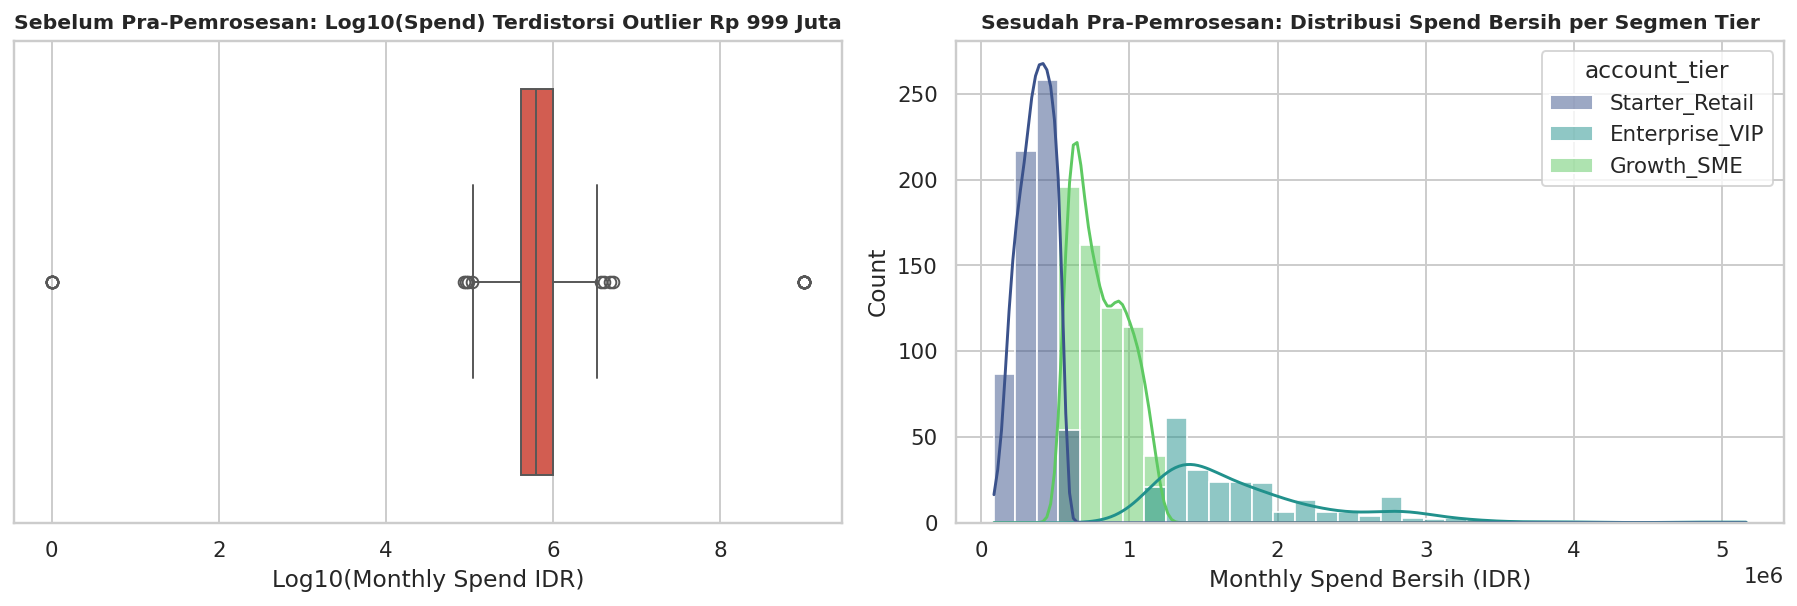

In [5]:
def preprocess_crispdm_pipeline(df_input):
    df = df_input.copy()
    
    df = df.drop_duplicates(subset=["customer_id"], keep="first").reset_index(drop=True)
    
    region_map = {
        "jkt": "DKI Jakarta",
        "Jakarta": "DKI Jakarta",
        "bengkulu kota": "Bengkulu"
    }
    df["region"] = df["region"].replace(region_map)
    
    valid_age_median = df.loc[(df["age_years"] >= 18) & (df["age_years"] <= 90), "age_years"].median()
    df["age_years_clean"] = np.where((df["age_years"] < 18) | (df["age_years"] > 90), valid_age_median, df["age_years"])
    
    valid_spend = df.loc[(df["monthly_spend_idr"] > 0) & (df["monthly_spend_idr"] < 5e7), "monthly_spend_idr"]
    spend_q99 = valid_spend.quantile(0.99)
    spend_median = valid_spend.median()
    df["monthly_spend_clean"] = np.where(
        df["monthly_spend_idr"] <= 0, spend_median,
        np.where(df["monthly_spend_idr"] > 5e7, spend_q99, df["monthly_spend_idr"])
    )
    
    df["account_tier"] = np.where(df["monthly_spend_clean"] > 1200000, "Enterprise_VIP",
                         np.where(df["monthly_spend_clean"] > 550000, "Growth_SME", "Starter_Retail"))
    
    df["recency_days"] = df.groupby("account_tier")["recency_days"].transform(lambda x: x.fillna(x.median()))
    df["csat_score"] = df.groupby("complaint_tickets")["csat_score"].transform(lambda x: x.fillna(x.median()))
    df["csat_score"] = df["csat_score"].fillna(df["csat_score"].median())
    
    df["rfm_composite_score"] = (
        0.35 * (1.0 / (1.0 + df["recency_days"] / 30.0)) +
        0.35 * (df["order_freq_90d"] / df["order_freq_90d"].max()) +
        0.30 * (np.log1p(df["monthly_spend_clean"]) / np.log1p(df["monthly_spend_clean"]).max())
    ).round(4)
    df["complaint_per_order"] = (df["complaint_tickets"] / (df["order_freq_90d"] + 1.0)).round(4)
    df["estimated_6m_ltv_idr"] = (df["monthly_spend_clean"] * 6.0 * 0.32).round(0)
    
    return df

df_clean = preprocess_crispdm_pipeline(df_raw)
print("=== PERBANDINGAN SEBELUM VS SESUDAH PRA-PEMROSESAN ===")
print(f"Baris Sebelum: {len(df_raw)} -> Baris Sesudah Deduplikasi: {len(df_clean)}")
print(f"Rata-rata Spend Mentah (Bias Outlier): Rp {df_raw['monthly_spend_idr'].mean():,.0f}")
print(f"Rata-rata Spend Bersih (Tervalidasi) : Rp {df_clean['monthly_spend_clean'].mean():,.0f}")
print(f"Total Missing Values Tersisa         : {df_clean.isna().sum().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=np.log10(np.maximum(1, df_raw["monthly_spend_idr"])), ax=axes[0], color="#e74c3c")
axes[0].set_title("Sebelum Pra-Pemrosesan: Log10(Spend) Terdistorsi Outlier Rp 999 Juta", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Log10(Monthly Spend IDR)")

sns.histplot(data=df_clean, x="monthly_spend_clean", hue="account_tier", bins=35, kde=True, ax=axes[1], palette="viridis")
axes[1].set_title("Sesudah Pra-Pemrosesan: Distribusi Spend Bersih per Segmen Tier", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Monthly Spend Bersih (IDR)")
plt.tight_layout()
plt.show()

### Tahap 4 & 5 CRISP-DM: Pemodelan Prediktif, Evaluasi Kurva Profit, & Kolaborasi AI + Manusia
Kita membuktikan secara kuantitatif mengapa pemodelan pada data yang telah melewati *Sanity Check* jauh lebih akurat dibandingkan data mentah. Selanjutnya, kita menggabungkan **AI Rule Synthesis** dengan **Validasi Keputusan Manusia (*Human-in-the-Loop*)** untuk menentukan ambang batas (*threshold*) intervensi retensi yang menghasilkan **ROI Rupiah tertinggi**.

=== EVALUASI MODEL PREDIKTIF (TEST SET N = 375 PELANGGAN) ===
ROC-AUC Model Tanpa Sanity Check (Data Mentah) : 0.8373
ROC-AUC Model CRISP-DM (Data Bersih + RFM)     : 0.8545 (+1.72% Peningkatan)
\nThreshold Standar (0.50) menghasilkan Net Profit Retensi : Rp 7,764,845
Threshold Optimal Bisnis (0.27) menghasilkan Net Profit  : Rp 13,493,645

Distribusi Keputusan Kolaborasi AI + Pengawasan Manusia (Test Set):
keputusan_akhir
Pertahankan_Reguler                                281
Intervensi_Promo_Otomatis_AI                        69
Eskalasi_Account_Manager_Manusia (VIP Override)     25


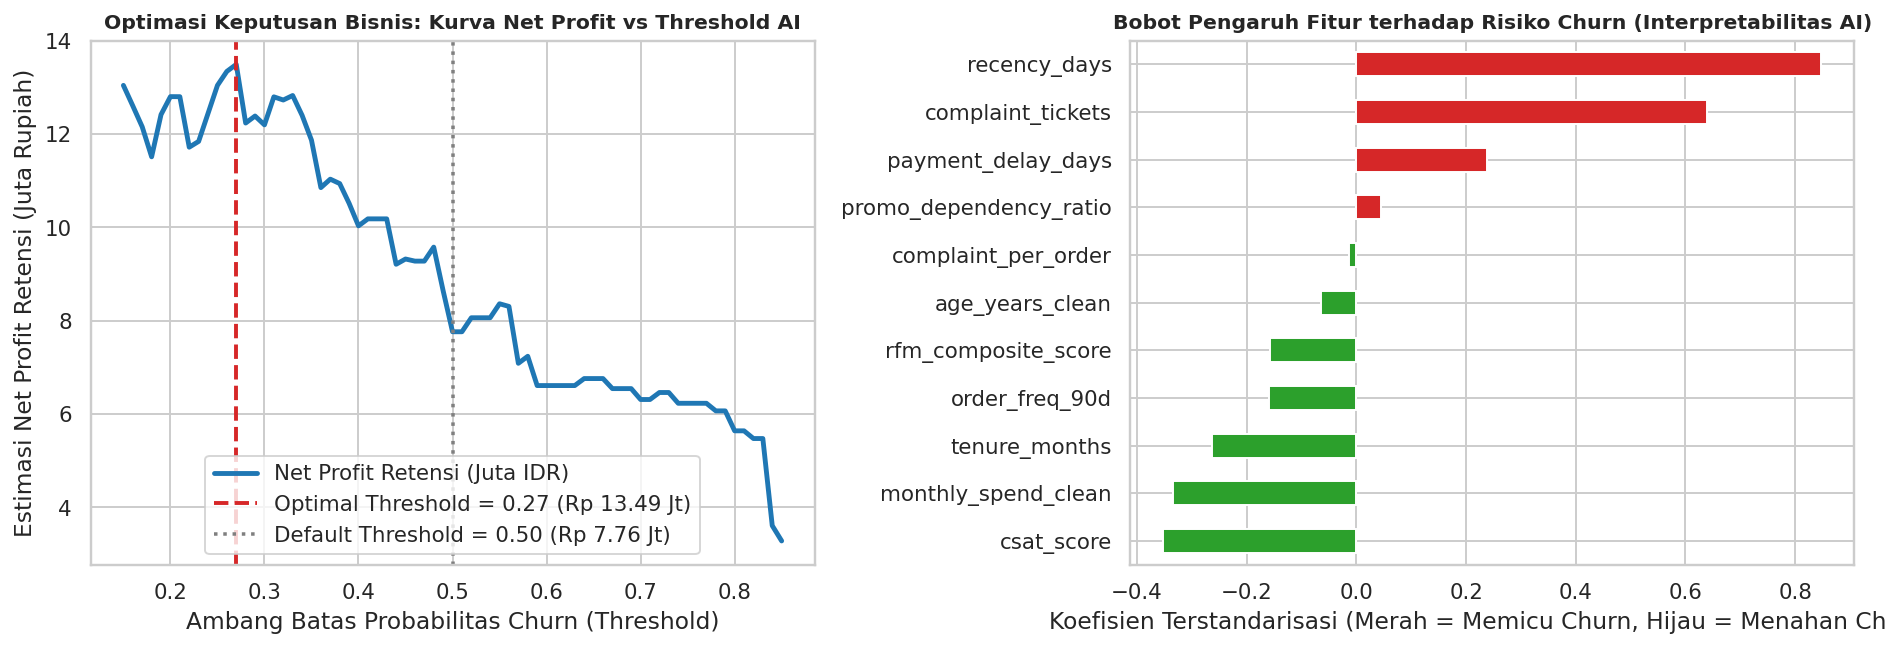

In [7]:
def standardize_matrix(X_train, X_test):
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0) + 1e-8
    return (X_train - mu) / sigma, (X_test - mu) / sigma, mu, sigma

def fit_regularized_logistic_gd(X, y, lr=0.15, epochs=900, l2_reg=0.01):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    for _ in range(epochs):
        z = np.clip(X @ w + b, -30, 30)
        preds = 1.0 / (1.0 + np.exp(-z))
        err = preds - y
        dw = (X.T @ err) / n_samples + l2_reg * w
        db = np.mean(err)
        w -= lr * dw
        b -= lr * db
    return w, b

def compute_roc_auc(y_true, y_prob):
    pos = y_prob[y_true == 1]
    neg = y_prob[y_true == 0]
    if len(pos) == 0 or len(neg) == 0:
        return 0.5
    diff = pos[:, None] - neg[None, :]
    return float(np.mean((diff > 0).astype(float) + 0.5 * (diff == 0).astype(float)))

np.random.seed(42)
perm = np.random.permutation(len(df_clean))
split_idx = int(0.75 * len(df_clean))
train_idx, test_idx = perm[:split_idx], perm[split_idx:]

raw_dedup = df_raw.drop_duplicates(subset=["customer_id"], keep="first").reset_index(drop=True)
raw_features = ["age_years", "tenure_months", "monthly_spend_idr", "order_freq_90d",
                "recency_days", "complaint_tickets", "csat_score", "payment_delay_days", "promo_dependency_ratio"]
X_raw = raw_dedup[raw_features].fillna(0).values
y_all = df_clean["churn_actual"].values
Xr_tr, Xr_te, _, _ = standardize_matrix(X_raw[train_idx], X_raw[test_idx])
wr, br = fit_regularized_logistic_gd(Xr_tr, y_all[train_idx])
prob_raw_te = 1.0 / (1.0 + np.exp(-np.clip(Xr_te @ wr + br, -30, 30)))
auc_raw = compute_roc_auc(y_all[test_idx], prob_raw_te)

clean_features = ["age_years_clean", "tenure_months", "monthly_spend_clean", "order_freq_90d",
                  "recency_days", "complaint_tickets", "csat_score", "payment_delay_days",
                  "promo_dependency_ratio", "rfm_composite_score", "complaint_per_order"]
X_clean = df_clean[clean_features].values
Xc_tr, Xc_te, _, _ = standardize_matrix(X_clean[train_idx], X_clean[test_idx])
wc, bc = fit_regularized_logistic_gd(Xc_tr, y_all[train_idx])
prob_clean_te = 1.0 / (1.0 + np.exp(-np.clip(Xc_te @ wc + bc, -30, 30)))
auc_clean = compute_roc_auc(y_all[test_idx], prob_clean_te)

print("=== EVALUASI MODEL PREDIKTIF (TEST SET N = 375 PELANGGAN) ===")
print(f"ROC-AUC Model Tanpa Sanity Check (Data Mentah) : {auc_raw:.4f}")
print(f"ROC-AUC Model CRISP-DM (Data Bersih + RFM)     : {auc_clean:.4f} (+{(auc_clean-auc_raw)*100:.2f}% Peningkatan)")

df_test = df_clean.iloc[test_idx].copy()
df_test["churn_prob_ai"] = prob_clean_te

thresholds = np.linspace(0.15, 0.85, 71)
net_profits = []
RETENTION_COST = 150_000.0
SUCCESS_RATE = 0.45

for th in thresholds:
    targeted = df_test["churn_prob_ai"] >= th
    saved_ltv = np.where(targeted & (df_test["churn_actual"] == 1),
                         SUCCESS_RATE * df_test["estimated_6m_ltv_idr"] - RETENTION_COST,
                         np.where(targeted & (df_test["churn_actual"] == 0), -RETENTION_COST, 0.0))
    net_profits.append(saved_ltv.sum())

best_idx = int(np.argmax(net_profits))
best_th = thresholds[best_idx]
max_profit = net_profits[best_idx]
default_profit = net_profits[int(np.argmin(np.abs(thresholds - 0.50)))]

df_test["keputusan_akhir"] = np.where(
    (df_test["account_tier"] == "Enterprise_VIP") & (df_test["complaint_tickets"] >= 2),
    "Eskalasi_Account_Manager_Manusia (VIP Override)",
    np.where(df_test["churn_prob_ai"] >= best_th, "Intervensi_Promo_Otomatis_AI", "Pertahankan_Reguler")
)

print(f"\\nThreshold Standar (0.50) menghasilkan Net Profit Retensi : Rp {default_profit:,.0f}")
print(f"Threshold Optimal Bisnis ({best_th:.2f}) menghasilkan Net Profit  : Rp {max_profit:,.0f}")
print("\nDistribusi Keputusan Kolaborasi AI + Pengawasan Manusia (Test Set):")
print(df_test["keputusan_akhir"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].plot(thresholds, np.array(net_profits) / 1e6, color="#1f77b4", lw=2.5, label="Net Profit Retensi (Juta IDR)")
axes[0].axvline(best_th, color="#d62728", ls="--", lw=2, label=f"Optimal Threshold = {best_th:.2f} (Rp {max_profit/1e6:.2f} Jt)")
axes[0].axvline(0.50, color="#7f7f7f", ls=":", lw=1.8, label=f"Default Threshold = 0.50 (Rp {default_profit/1e6:.2f} Jt)")
axes[0].set_title("Optimasi Keputusan Bisnis: Kurva Net Profit vs Threshold AI", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Ambang Batas Probabilitas Churn (Threshold)")
axes[0].set_ylabel("Estimasi Net Profit Retensi (Juta Rupiah)")
axes[0].legend(loc="lower center")

feat_imp = pd.Series(wc, index=clean_features).sort_values()
colors = ["#2ca02c" if v < 0 else "#d62728" for v in feat_imp.values]
feat_imp.plot(kind="barh", ax=axes[1], color=colors)
axes[1].set_title("Bobot Pengaruh Fitur terhadap Risiko Churn (Interpretabilitas AI)", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Koefisien Terstandarisasi (Merah = Memicu Churn, Hijau = Menahan Churn)")
plt.tight_layout()
plt.show()